# 06 · Price model: deeper tests

Notebook 03 found seasonal-naive beats Prophet at 4–12 months ahead (17.3% vs 22.9% median MAPE). Can anything beat
seasonal-naive? We test what the forecasting literature says works on monthly series:

- **Statistical methods:** AutoETS, AutoARIMA and AutoTheta (seasonal, period 12), from `statsforecast`.
  Theta won M3, and ETS/ARIMA/Theta were the backbone of the M4 benchmarks (Makridakis et al., 2020).
- **Combinations:** in M4, 12 of the 17 most accurate methods were combinations. We test the mean and the median of
  ETS, ARIMA and Theta (close to the SCUM benchmark of Petropoulos & Svetunkov, 2020), plus that median with seasonal-naive added.
- **Global LightGBM:** M5 was won by LightGBM models trained across many series at once (In & Jung), and 45 of the top 50
  used LightGBM. We train one direct multi-horizon model across all crop × state series.
- **Baselines:** naive and seasonal-naive. Recent mandi studies found naive hard to beat (Assam weekly prices: naive 16.6%
  MAPE beat LightGBM, ETS and Chronos-2).

Same backtest as notebook 03: cutoffs May 2024, Nov 2024, May 2025; 12 months ahead; series with ≥ 24 observed months
before the cutoff; scored at **4–12 months ahead**. Gaps inside a series are filled by log-linear interpolation (needed
by ETS/ARIMA), and every method uses the same filled history. Scored with MAPE and MASE (Hyndman & Koehler, 2006;
scaled by in-sample seasonal-naive error, so it doesn't favour cheap crops the way MAPE can).

In [1]:
import sys
sys.path.insert(0, '../project')
import os
import warnings
from pathlib import Path

os.environ['NIXTLA_ID_AS_COL'] = '1'
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, AutoETS, AutoTheta, Naive, SeasonalNaive

import data

warnings.filterwarnings('ignore')
SEED = 42
RESULTS, FIGS = Path('../research/results'), Path('../research/figures')
CUTOFFS = pd.to_datetime(['2024-05-01', '2024-11-01', '2025-05-01'])
H, MIN_TRAIN = 12, 24
pd.set_option('display.width', 220)

In [2]:
prices = data.mandi_prices()
national = (prices.assign(w=prices.price * prices.n).groupby(['crop', 'month'])[['w', 'n']].sum()
            .eval('price = w / n').reset_index()[['crop', 'month', 'price']].assign(state='All India'))
series = pd.concat([prices[['crop', 'state', 'month', 'price']], national])
series['unique_id'] = series.crop + '|' + series.state
obs = series.set_index(['unique_id', 'month']).price.sort_index()


def filled(cut):
    """Log prices up to `cut` for every series with >= MIN_TRAIN observed months, monthly, gaps interpolated, carried to `cut`."""
    out = []
    for uid, s in obs.groupby(level=0):
        s = s.droplevel(0)
        s = s[s.index <= cut]
        if len(s) < MIN_TRAIN:
            continue
        idx = pd.date_range(s.index.min(), cut, freq='MS')
        out.append(pd.DataFrame({'unique_id': uid, 'ds': idx, 'y': np.log(s).reindex(idx).interpolate().ffill().values}))
    return pd.concat(out, ignore_index=True)

print(obs.index.get_level_values(0).nunique(), 'series')

707 series


## 1. Statistical methods and combinations

In [3]:
stat_models = [Naive(), SeasonalNaive(season_length=12), AutoETS(season_length=12),
               AutoARIMA(season_length=12), AutoTheta(season_length=12)]
fc_parts, train_hist = [], {}
for cut in CUTOFFS:
    tr = filled(cut)
    train_hist[cut] = tr
    sf = StatsForecast(models=stat_models, freq='MS', n_jobs=-1)
    f = sf.forecast(df=tr, h=H)
    f['cutoff'] = cut
    fc_parts.append(f)
fc = pd.concat(fc_parts, ignore_index=True)
fc = fc.rename(columns={'Naive': 'naive', 'SeasonalNaive': 'seasonal_naive', 'AutoETS': 'ets', 'AutoARIMA': 'arima', 'AutoTheta': 'theta'})
fc['combo_mean'] = fc[['ets', 'arima', 'theta']].mean(axis=1)
fc['combo_median'] = fc[['ets', 'arima', 'theta']].median(axis=1)
fc['combo_median_snaive'] = fc[['ets', 'arima', 'theta', 'seasonal_naive']].median(axis=1)
print(fc.shape)

(15744, 11)


## 2. Global LightGBM (direct, all horizons in one model)

One row per (series, origin month t, horizon h): features are the last 12 log-price changes relative to t,
the same-month-last-year signal, target month, h, and crop. Target: log(price at t+h) − log(price at t).
Only origins with t + h ≤ cutoff are used for training, so nothing from the test period leaks in.

In [4]:
def lgb_rows(df, origins_upto, horizon_rows=True):
    rows = []
    for uid, g in df.groupby('unique_id'):
        y = g.y.values
        ds = g.ds.values
        crop = uid.split('|')[0]
        for t in range(12, len(y)):
            base = {f'lag{k}': y[t - k] - y[t] for k in range(1, 13)}
            for h in range(1, H + 1):
                target_ds = pd.Timestamp(ds[t]) + pd.DateOffset(months=h)
                if horizon_rows and target_ds > origins_upto:
                    break
                if not horizon_rows and t != len(y) - 1:
                    break
                r = dict(base, h=h, month=target_ds.month, crop=crop, snaive=y[t + h - 12] - y[t] if t + h - 12 < len(y) else np.nan,
                         unique_id=uid, ds=target_ds, level=y[t])
                if horizon_rows:
                    r['target'] = y[t + h] - y[t]
                rows.append(r)
    out = pd.DataFrame(rows)
    out['crop'] = out.crop.astype('category')
    return out


lgb_parts = []
for cut in CUTOFFS:
    tr = train_hist[cut]
    train = lgb_rows(tr, cut)
    test = lgb_rows(tr, cut, horizon_rows=False)
    test['crop'] = pd.Categorical(test.crop, categories=train.crop.cat.categories)
    feats = [c for c in train.columns if c not in ('target', 'unique_id', 'ds', 'level')]
    m = lgb.LGBMRegressor(objective='l1', n_estimators=500, learning_rate=0.03, num_leaves=31, min_child_samples=50,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
    m.fit(train[feats], train.target)
    lgb_parts.append(pd.DataFrame({'unique_id': test.unique_id, 'ds': test.ds, 'cutoff': cut,
                                   'lightgbm': test.level + m.predict(test[feats])}))
    print(cut.date(), len(train), 'training rows')
fc = fc.merge(pd.concat(lgb_parts), on=['unique_id', 'ds', 'cutoff'], how='left')

2024-05-01 106092 training rows


2024-11-01 141414 training rows


2025-05-01 178722 training rows


## 3. Score

In [5]:
METHODS = ['naive', 'seasonal_naive', 'ets', 'arima', 'theta', 'combo_mean', 'combo_median', 'combo_median_snaive', 'lightgbm']
for m in METHODS:
    fc[m] = np.exp(fc[m])
act = obs.rename('actual').reset_index().rename(columns={'month': 'ds'})
bt = fc.merge(act, on=['unique_id', 'ds'])  # only months with a real observation
bt['h'] = (bt.ds.dt.year - bt.cutoff.dt.year) * 12 + bt.ds.dt.month - bt.cutoff.dt.month


def mase_scale(cut):
    """In-sample mean absolute seasonal difference per series (MASE denominator), in Rs."""
    tr = train_hist[cut].assign(p=lambda d: np.exp(d.y))
    return tr.groupby('unique_id').p.apply(lambda p: p.diff(12).abs().mean()).rename('scale').reset_index().assign(cutoff=cut)

bt = bt.merge(pd.concat(mase_scale(c) for c in CUTOFFS), on=['unique_id', 'cutoff'])
for m in METHODS:
    bt[f'ape_{m}'] = (bt[m] - bt.actual).abs() / bt.actual * 100
    bt[f'ase_{m}'] = (bt[m] - bt.actual).abs() / bt.scale
bt = bt.dropna(subset=[f'ape_{m}' for m in METHODS] + [f'ase_{m}' for m in METHODS])
harvest = bt[bt.h >= 4]
print(len(bt), 'forecast-months,', bt.unique_id.nunique(), 'series;', len(harvest), 'at 4-12 months')

14196 forecast-months, 450 series; 10674 at 4-12 months


In [6]:
ps_mape = harvest.groupby('unique_id')[[f'ape_{m}' for m in METHODS]].mean().set_axis(METHODS, axis=1)
ps_mase = harvest.groupby('unique_id')[[f'ase_{m}' for m in METHODS]].mean().set_axis(METHODS, axis=1)
is_nat = ps_mape.index.str.endswith('|All India')
table = pd.DataFrame({
    'median MAPE %': ps_mape.median(),
    'mean MAPE %': ps_mape.mean(),
    'median MASE': ps_mase.median(),
    'All-India median MAPE %': ps_mape[is_nat].median(),
    'mean rank (MAPE)': ps_mape.rank(axis=1).mean(),
    'beats seasonal-naive (% of series)': (ps_mape.lt(ps_mape.seasonal_naive, axis=0)).mean() * 100,
}).round(2).sort_values('median MAPE %')
table['Wilcoxon p vs seasonal-naive'] = [
    np.nan if m == 'seasonal_naive' else round(stats.wilcoxon(ps_mape[m], ps_mape.seasonal_naive).pvalue, 4) for m in table.index]
table.to_csv(RESULTS / '2026-11-06_price_model_tests.csv')
table

,median MAPE %,mean MAPE %,median MASE,All-India median MAPE %,mean rank (MAPE),beats seasonal-naive (% of series),Wilcoxon p vs seasonal-naive
combo_median_snaive,16.40,22.18,0.95,13.90,3.87,67.48,0.0000
combo_mean,16.66,22.75,0.97,13.02,4.52,62.81,0.0000
combo_median,17.43,24.35,0.97,15.08,4.95,55.68,0.1479
ets,17.46,23.97,0.97,14.18,4.39,59.91,0.0051
arima,17.62,23.70,1.03,16.20,5.20,50.78,0.9964
seasonal_naive,17.87,23.57,1.06,16.50,5.49,0.00,NaN
naive,18.11,25.52,1.03,16.84,4.81,56.12,0.7132
theta,18.51,25.66,1.05,15.63,6.06,47.66,0.0040
lightgbm,19.02,24.05,1.04,16.54,5.70,46.10,0.0377


,naive,seasonal_naive,ets,arima,theta,combo_mean,combo_median,combo_median_snaive,lightgbm
h,,,,,,,,,
1–3,9.5,17.0,9.2,10.3,9.5,9.2,9.1,9.1,10.7
4–6,15.1,17.1,14.3,14.8,15.8,14.3,14.4,14.4,16.2
7–12,18.4,17.9,17.5,18.4,18.5,17.1,18.1,16.5,19.4


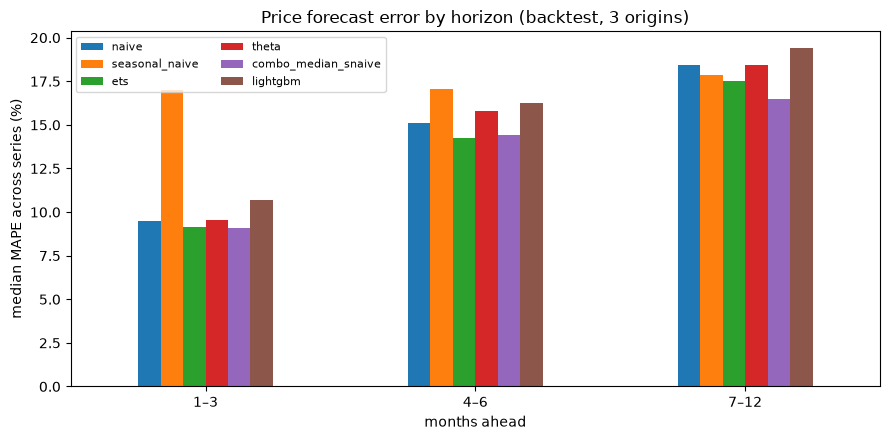

In [7]:
bands = pd.cut(bt.h, [0, 3, 6, 12], labels=['1–3', '4–6', '7–12'])
by_h = bt.groupby([bands, 'unique_id'], observed=True)[[f'ape_{m}' for m in METHODS]].mean().groupby(level=0).median().set_axis(METHODS, axis=1)
show = ['naive', 'seasonal_naive', 'ets', 'theta', 'combo_median_snaive', 'lightgbm']
ax = by_h[show].plot.bar(figsize=(9, 4.5), rot=0)
ax.set_xlabel('months ahead')
ax.set_ylabel('median MAPE across series (%)')
ax.set_title('Price forecast error by horizon (backtest, 3 origins)')
ax.legend(fontsize=8, ncols=2)
plt.tight_layout()
plt.savefig(FIGS / 'price_tests_by_horizon.png', dpi=150)
by_h.round(1)

Per crop (median over that crop's series, 4–12 months): does the winner change by crop type?

In [8]:
crop_of = ps_mape.index.str.split('|').str[0]
per_crop = ps_mape.groupby(crop_of).median()[show].round(1)
per_crop['best'] = per_crop.idxmin(axis=1)
per_crop.sort_values('seasonal_naive')

,naive,seasonal_naive,ets,theta,combo_median_snaive,lightgbm,best
unique_id,,,,,,,
lentil,3.4,5.2,3.4,3.5,3.4,4.7,naive
cotton,6.7,6.9,6.5,7.4,6.1,8.8,combo_median_snaive
rice,6.7,7.1,6.7,6.7,6.4,7.8,combo_median_snaive
wheat,8.7,8.3,8.3,10.0,8.6,9.3,seasonal_naive
ragi,7.0,8.9,7.0,5.3,6.8,8.1,theta
barley,7.5,9.0,7.9,7.7,7.2,10.2,combo_median_snaive
bajra,10.9,10.6,11.9,13.8,12.6,14.3,seasonal_naive
soybean,9.1,10.9,9.1,9.2,9.2,9.9,naive
mustard,8.4,11.4,8.4,9.8,8.7,12.6,naive


## 4. App forecast: the 12 months after the last month of data, with the median combination

The winner, the median of ETS, ARIMA, Theta and seasonal-naive, forecasts 12 months from the last month of data for
every series with ≥ 24 observed months **and** a price in the last 12 months (a series that stopped reporting would
otherwise be forecast from stale, carried-forward prices). `mape` is the series' backtest MAPE at 4–12 months.
This replaces the seasonal-naive file written by notebook 03.

Nov 6 re-run: prices after May 2026 come from data.gov.in's daily resource (`data.daily_prices`), up to Nov 5, so the
last month (Nov 2026) is partial and the forecast runs Dec 2026 – Nov 2027. Monthly values more than 5× off their
series median (unit slips) are dropped by `data.mandi_prices`.

In [9]:
last = obs.index.get_level_values('month').max()
recent = obs[obs.index.get_level_values('month') > last - pd.DateOffset(months=12)].index.get_level_values(0).unique()
hist = filled(last)
hist = hist[hist.unique_id.isin(recent)]
f = StatsForecast(models=stat_models[1:], freq='MS', n_jobs=-1).forecast(df=hist, h=H)
f['price'] = np.exp(f[['SeasonalNaive', 'AutoETS', 'AutoARIMA', 'AutoTheta']].median(axis=1)).round(0)
f[['crop', 'state']] = f.unique_id.str.split('|', expand=True)
f = f.rename(columns={'ds': 'month'}).assign(method='combo_median_snaive')
f['mape'] = f.unique_id.map(ps_mape.combo_median_snaive).round(1)

old = pd.read_csv('../data/processed/price_forecast.csv', parse_dates=['month'])
both = f.merge(old, on=['crop', 'state', 'month'], suffixes=('', '_old'))
print(f.unique_id.nunique(), 'series now,', old.groupby(['crop', 'state']).ngroups, 'in the old seasonal-naive file;',
      f'median |new − old| {((both.price - both.price_old).abs() / both.price_old).median() * 100:.1f}% of price')
f[['crop', 'state', 'month', 'price', 'method', 'mape']].to_csv('../data/processed/price_forecast.csv', index=False)
f[f.state == 'All India'].pivot(index='crop', columns='month', values='price').iloc[:, ::3]

467 series now, 469 in the old seasonal-naive file; median |new − old| 11.8% of price


month,2026-12-01,2027-03-01,2027-06-01,2027-09-01
crop,,,,
apple,9791.0,12847.0,15691.0,10336.0
bajra,2697.0,2669.0,2715.0,2741.0
banana,4983.0,5116.0,5252.0,5392.0
barley,2796.0,2764.0,2810.0,2822.0
blackgram,7840.0,7878.0,7894.0,7945.0
chickpea,6843.0,6844.0,6844.0,6844.0
coconut,6628.0,6628.0,6628.0,6682.0
coffee,21408.0,21294.0,21294.0,21300.0
cotton,8749.0,8644.0,8556.0,8670.0
